# Configuration


In [1]:
import sys
import os

import pickle
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.model_selection import GroupKFold
from IPython.display import display

project_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
if project_root not in sys.path:
    sys.path.append(project_root)

from src.config import DATA_DIR, SEED, MODELS_NEEDING_SCALING
from src.run_models import load_and_prep_data, clean_data, get_model_and_params, create_pipeline, generate_submission_file

sns.set_theme(style="whitegrid")
%matplotlib inline

In [2]:
PICKLE_FILE_NAME = 'CatBoostRegressor_tuning_study 97 some good categories.pkl'
PKL_PATH = DATA_DIR / 'models' / PICKLE_FILE_NAME
MODEL_NAME = 'CatBoostRegressor'

class Args:
    pkl_path = PICKLE_FILE_NAME
    fe_mode = 'cat'
    run_fe = True

args = Args()

train_df, true_test_df = load_and_prep_data(
    fe_mode=args.fe_mode, 
    force_run_fe=args.run_fe
)

cols_to_drop = ['nickname', 'first']

X, y, _, _, groups = clean_data(
    train_df, true_test_df, cols_to_drop
)

print(f"Data Loaded. Shape: {X.shape}")


--- Loading and prepping data for mode: cat ---
Running cat feature engineering pipeline (forced)...
Building feature engineering pipeline in cat mode...
-------------------- train_df_shape: (100820, 115) --------------------
-------------------- test_df_shape: (44726, 115) --------------------
Feature engineering completed in 93.11 seconds.
Saving processed files to C:\Users\selad\Downloads\sanityCheck\ScrabbleEX\data\processed directory.
Removed 11458 rows belonging to casual-only players.
Data Loaded. Shape: (38952, 111)


# Running the analysis on 5 folds and plotting results

Best params from study: {'iterations': 388, 'depth': 7, 'learning_rate': 0.020042055065074078, 'l2_leaf_reg': 6.5325119246911125, 'border_count': 80}

==================== FOLD 1/5 ====================
Training set: (31161, 111)
Validation set: (7791, 111)
Distinct players in Val: 163

--- Metrics ---
Train RMSE: 58.2743
Val   RMSE: 111.2847
Gap: 53.0104

Top 10 Worst Predictions (Fold 1):


,nickname,Actual,Predicted,Error
27214,cayden,1322,2066.468087,-744.468087
36673,cayden,1335,2027.987434,-692.987434
6323,cayden,1318,1997.332047,-679.332047
24734,cayden,1319,1982.583923,-663.583923
35313,cayden,1325,1977.353214,-652.353214
37953,angellharvv,1961,1397.517586,563.482414
29417,wordhero,1186,1748.598409,-562.598409
24703,wordhero,1188,1746.109462,-558.109462
28450,wordhero,1191,1743.973600,-552.973600
36560,wordhero,1191,1742.870317,-551.870317


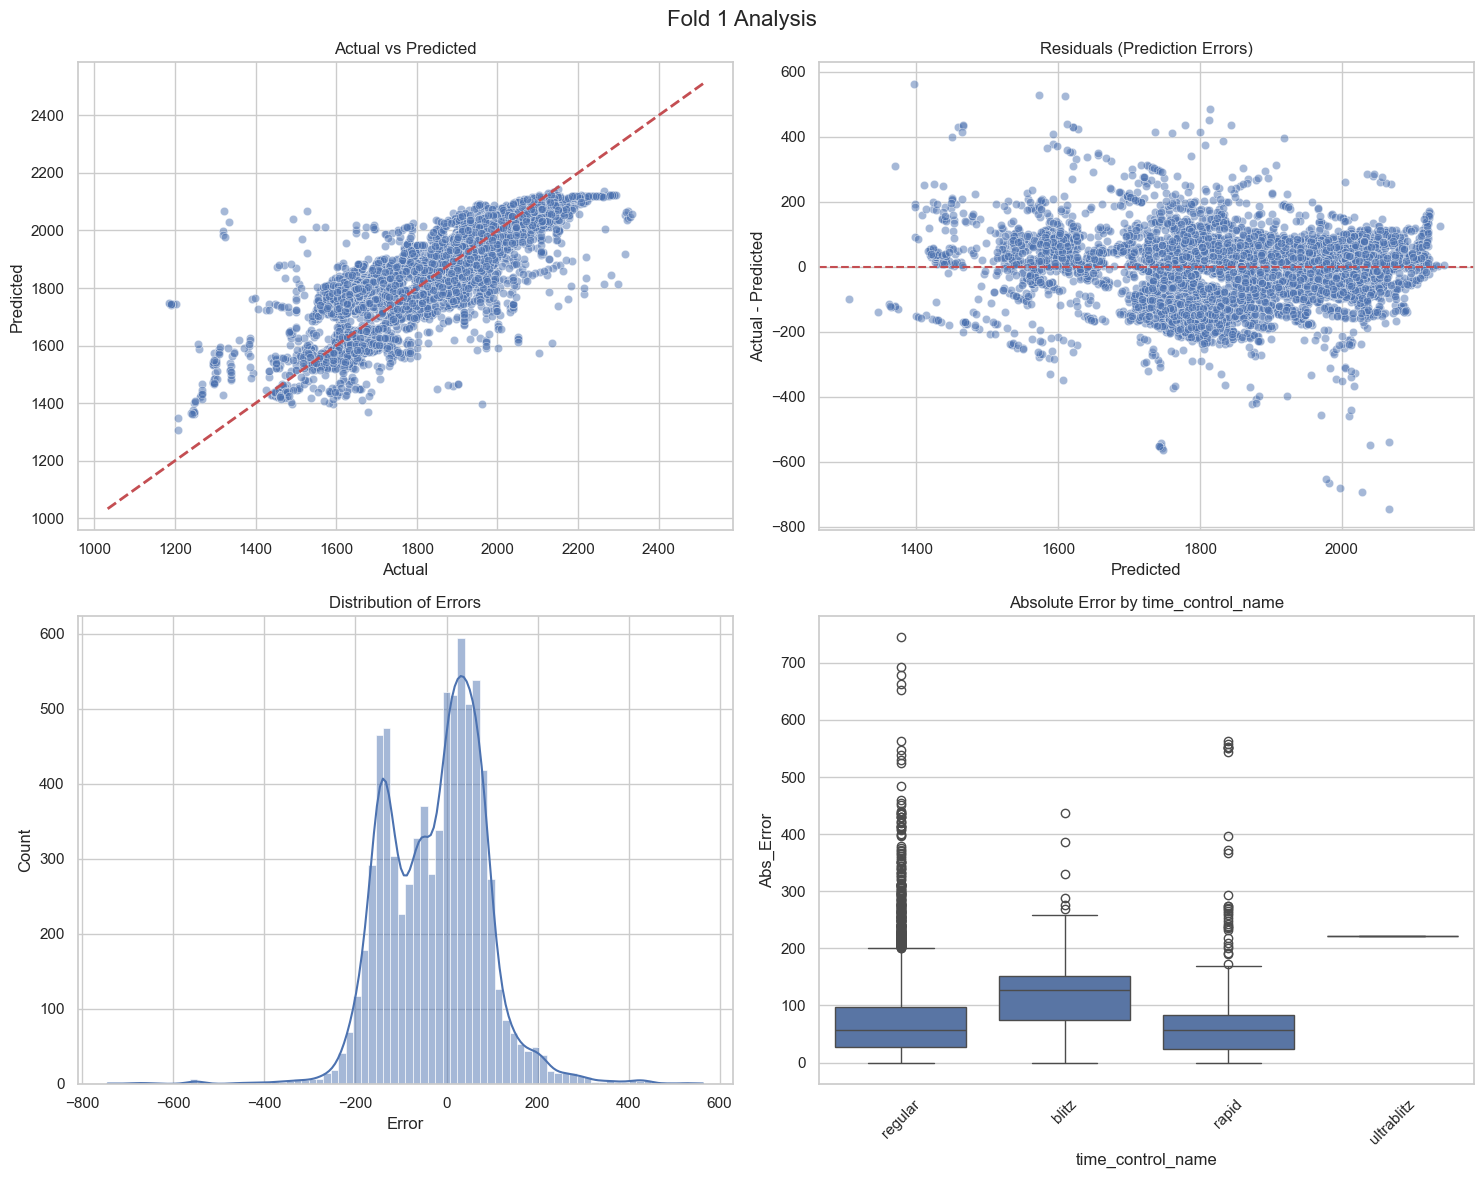

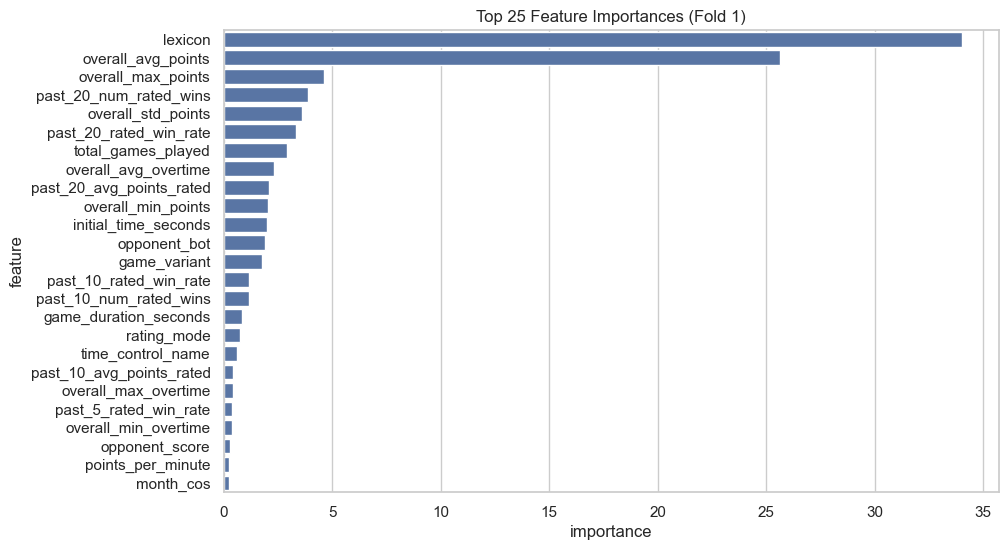


==================== FOLD 2/5 ====================
Training set: (31161, 111)
Validation set: (7791, 111)
Distinct players in Val: 166

--- Metrics ---
Train RMSE: 60.8172
Val   RMSE: 117.3121
Gap: 56.4950

Top 10 Worst Predictions (Fold 2):


,nickname,Actual,Predicted,Error
23643,Pasindu,2510,1607.002471,902.997529
28114,Pasindu,2510,1613.369612,896.630388
12239,Pasindu,2510,1615.746496,894.253504
8864,Pasindu,2510,1615.812271,894.187729
36357,Pasindu,2510,1616.190737,893.809263
696,Pasindu,2510,1616.223269,893.776731
20161,Pasindu,2510,1617.298273,892.701727
17135,Pasindu,2510,1618.018315,891.981685
8509,Pasindu,2289,1605.336855,683.663145
34191,Pasindu,2289,1621.865846,667.134154


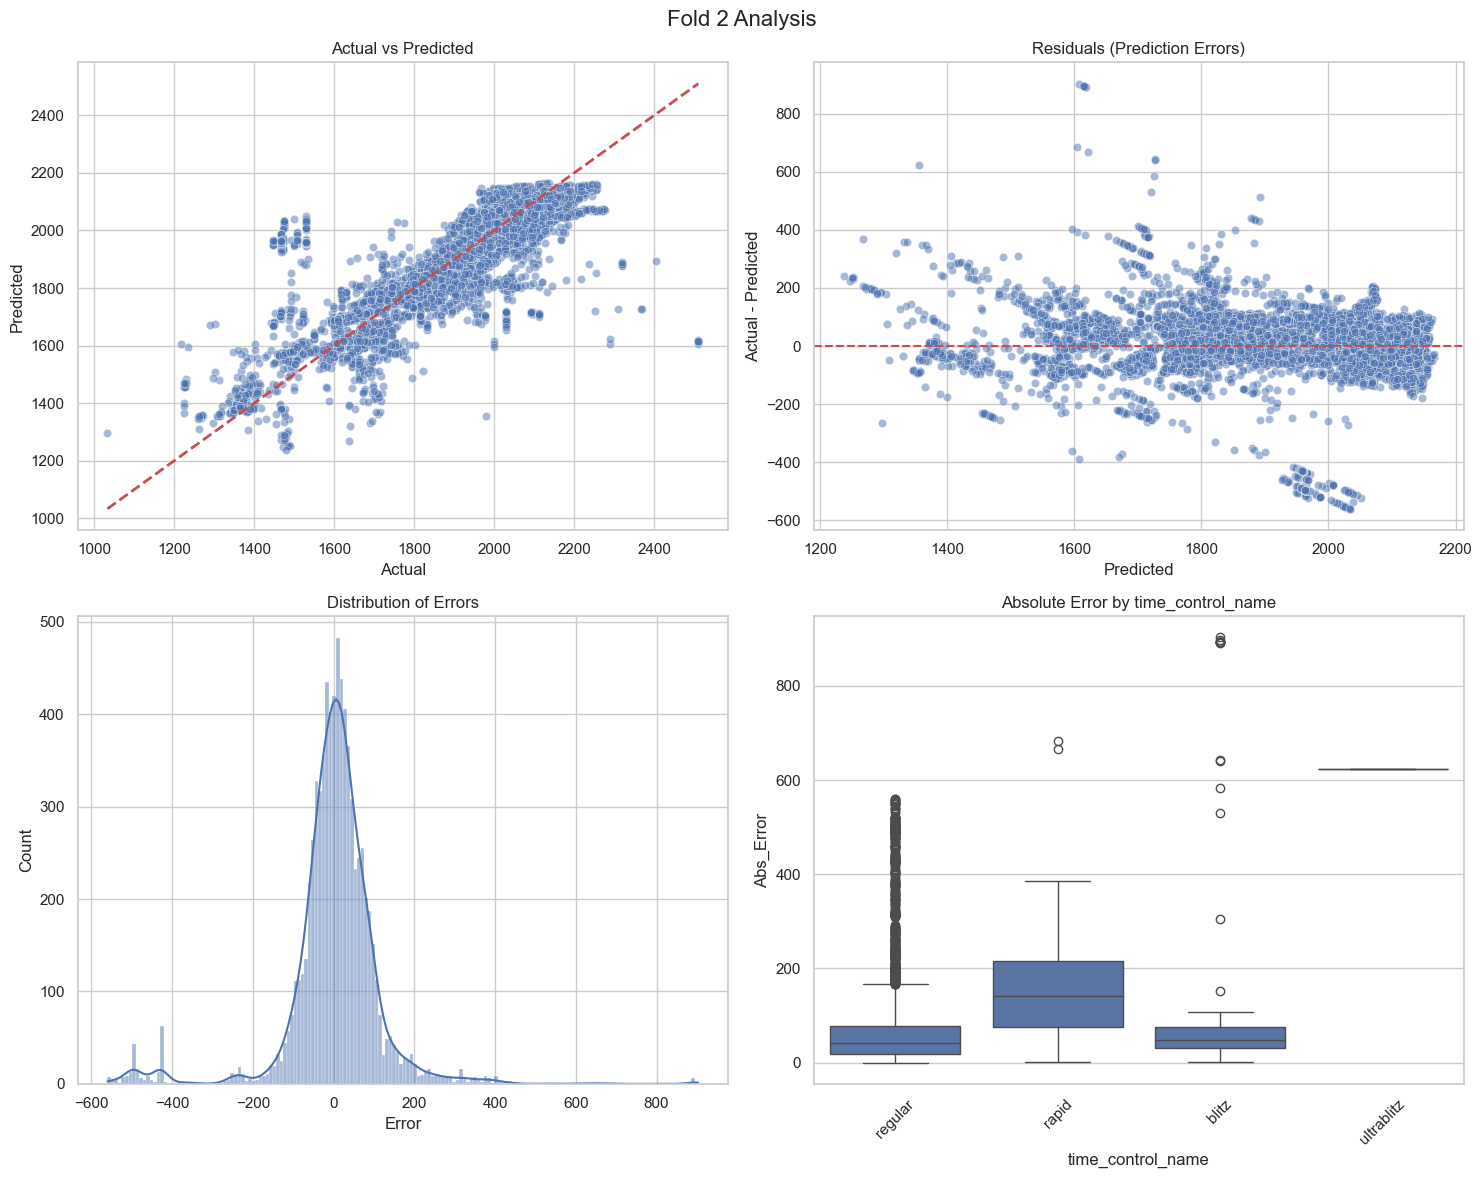

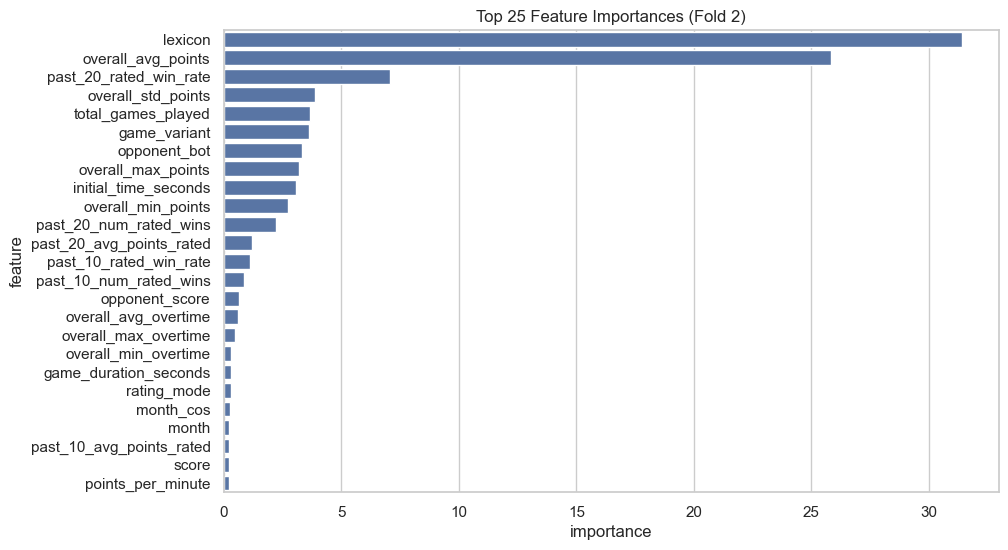


==================== FOLD 3/5 ====================
Training set: (31162, 111)
Validation set: (7790, 111)
Distinct players in Val: 166

--- Metrics ---
Train RMSE: 61.7861
Val   RMSE: 91.5020
Gap: 29.7159

Top 10 Worst Predictions (Fold 3):


,nickname,Actual,Predicted,Error
32771,smol1,1444,1910.964654,-466.964654
186,NdiranguKaranjq,1241,1687.430491,-446.430491
34071,NdiranguKaranjq,1239,1683.502849,-444.502849
34951,NdiranguKaranjq,1248,1688.528907,-440.528907
8616,NdiranguKaranjq,1243,1670.771760,-427.771760
34381,NdiranguKaranjq,1239,1654.164392,-415.164392
21071,gregthaopenny,1500,1912.341814,-412.341814
34175,kurgan,2116,1712.121797,403.878203
25951,SM_ROMPIN,1258,1639.678697,-381.678697
36590,mishu7,1500,1881.396631,-381.396631


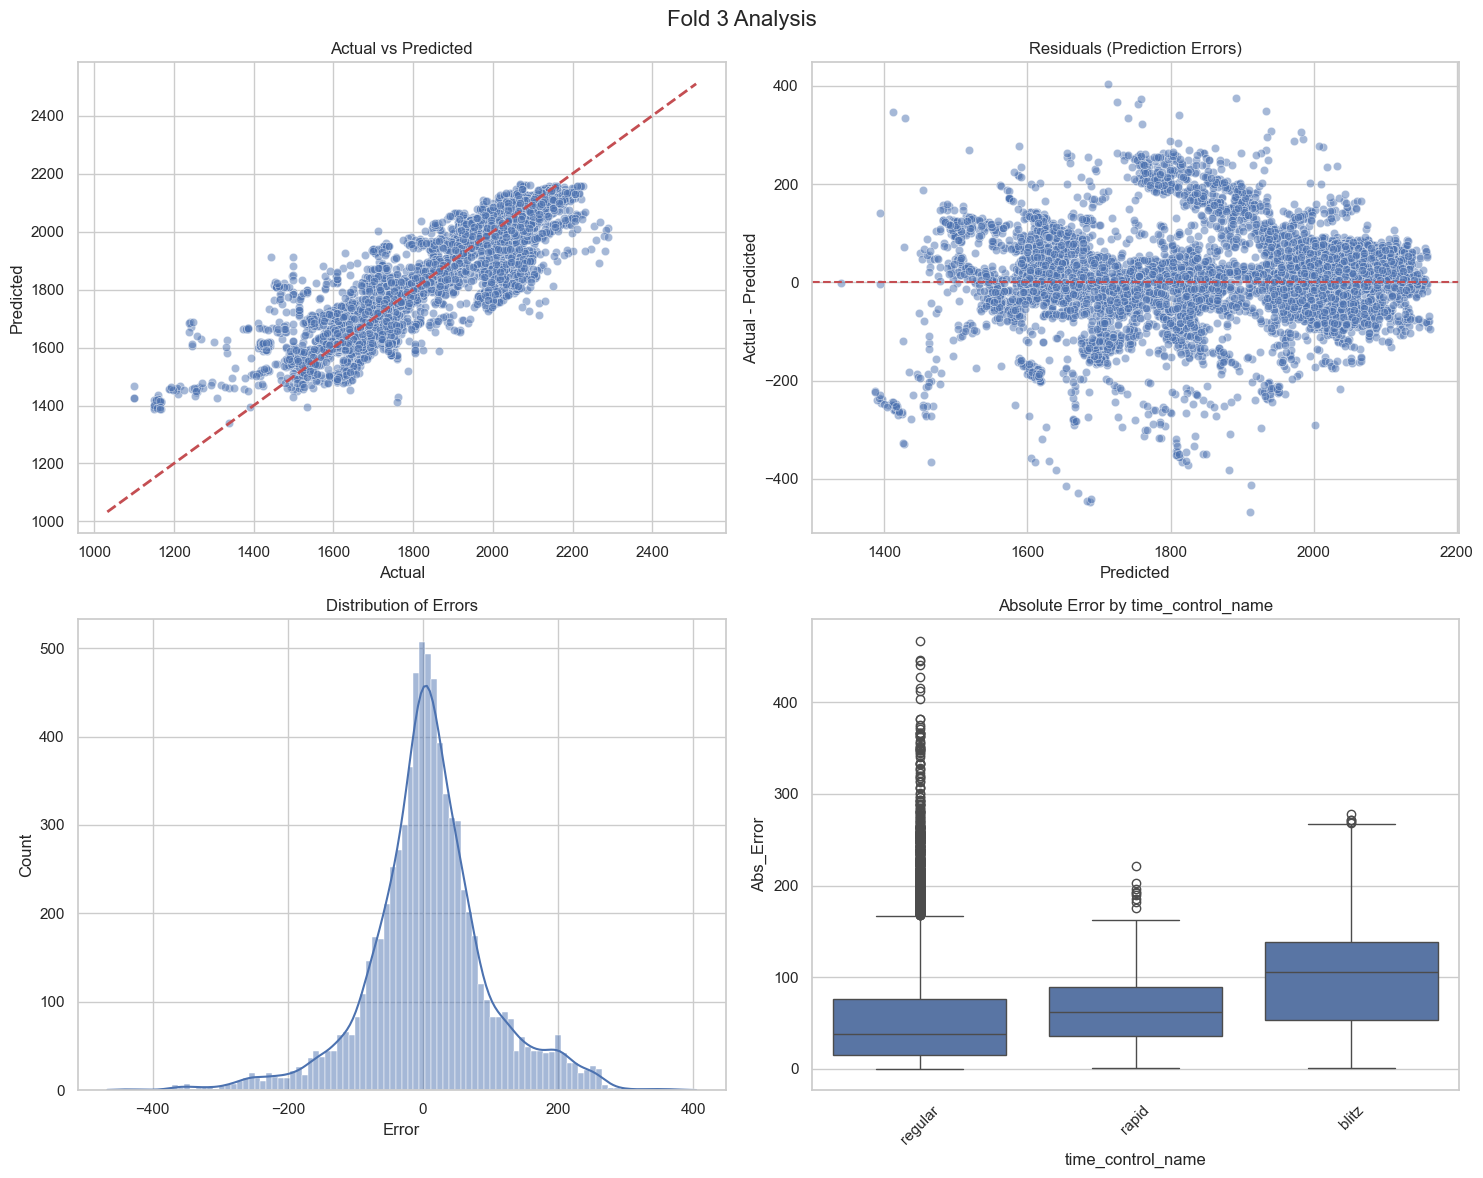

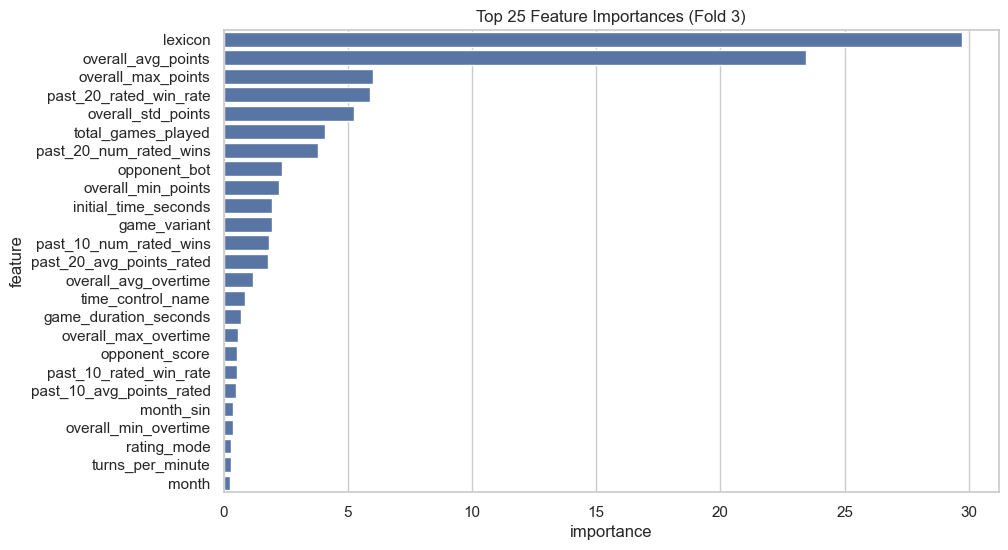


==================== FOLD 4/5 ====================
Training set: (31162, 111)
Validation set: (7790, 111)
Distinct players in Val: 166

--- Metrics ---
Train RMSE: 60.7195
Val   RMSE: 99.9142
Gap: 39.1947

Top 10 Worst Predictions (Fold 4):


,nickname,Actual,Predicted,Error
15403,aarrgh,1166,1910.235697,-744.235697
8776,aarrgh,1179,1912.312020,-733.312020
13758,aarrgh,1182,1911.791457,-729.791457
6431,aarrgh,1173,1898.549830,-725.549830
2182,aarrgh,1185,1889.286883,-704.286883
10062,JackHKeynes,1353,1963.786437,-610.786437
36509,aarrgh,1325,1919.033894,-594.033894
38713,aarrgh,1330,1911.621191,-581.621191
9678,aarrgh,1341,1909.019222,-568.019222
19023,rishabbhandari80,1299,1836.464623,-537.464623


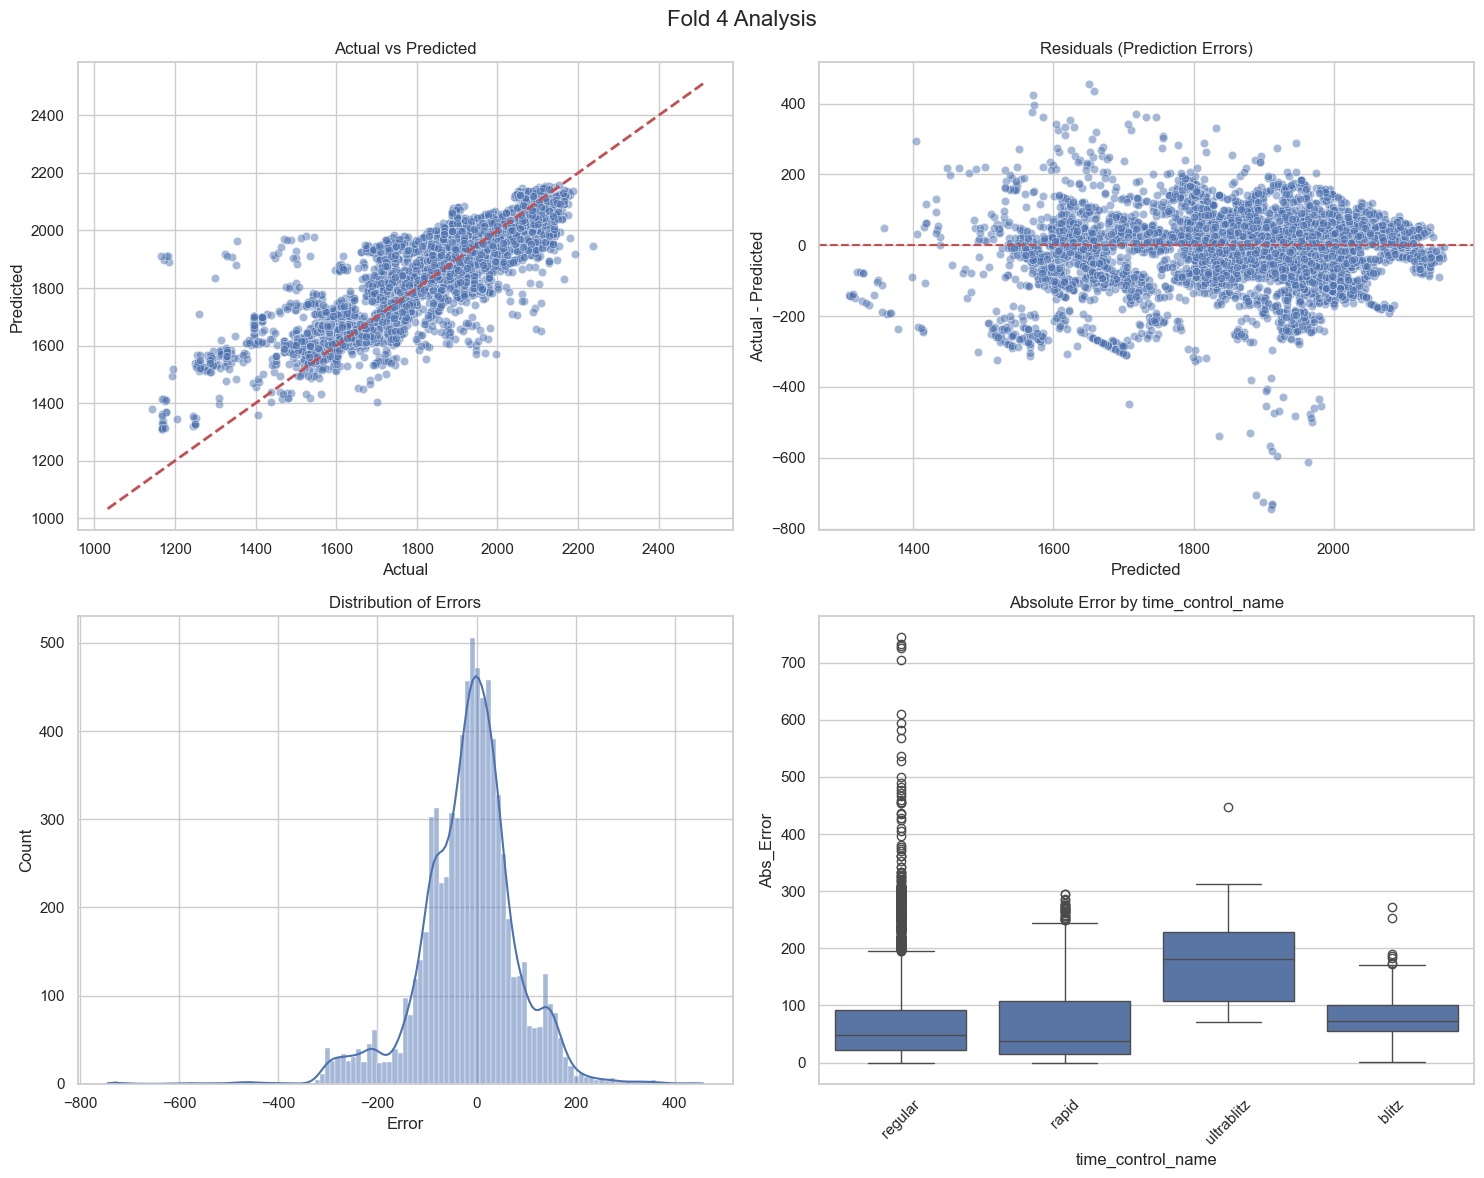

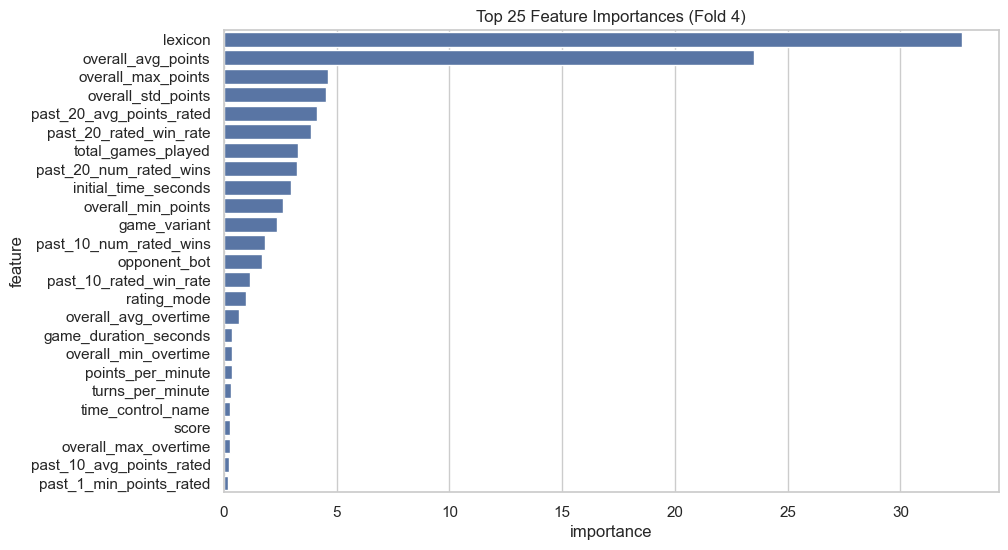


==================== FOLD 5/5 ====================
Training set: (31162, 111)
Validation set: (7790, 111)
Distinct players in Val: 166

--- Metrics ---
Train RMSE: 59.8249
Val   RMSE: 97.0499
Gap: 37.2249

Top 10 Worst Predictions (Fold 5):


,nickname,Actual,Predicted,Error
17697,SmartGoose,1315,1769.562399,-454.562399
34340,MEHAAN,2145,1712.983160,432.016840
4116,MEHAAN,2145,1725.911998,419.088002
31404,patricck,2289,1877.498432,411.501568
14793,MEHAAN,2145,1736.979532,408.020468
7144,Yuki86,1265,1672.082270,-407.082270
499,MEHAAN,2116,1712.531810,403.468190
18591,Pluperfect,2008,1606.564200,401.435800
14578,Anita_H,1500,1901.070573,-401.070573
22344,Pluperfect,2012,1612.383371,399.616629


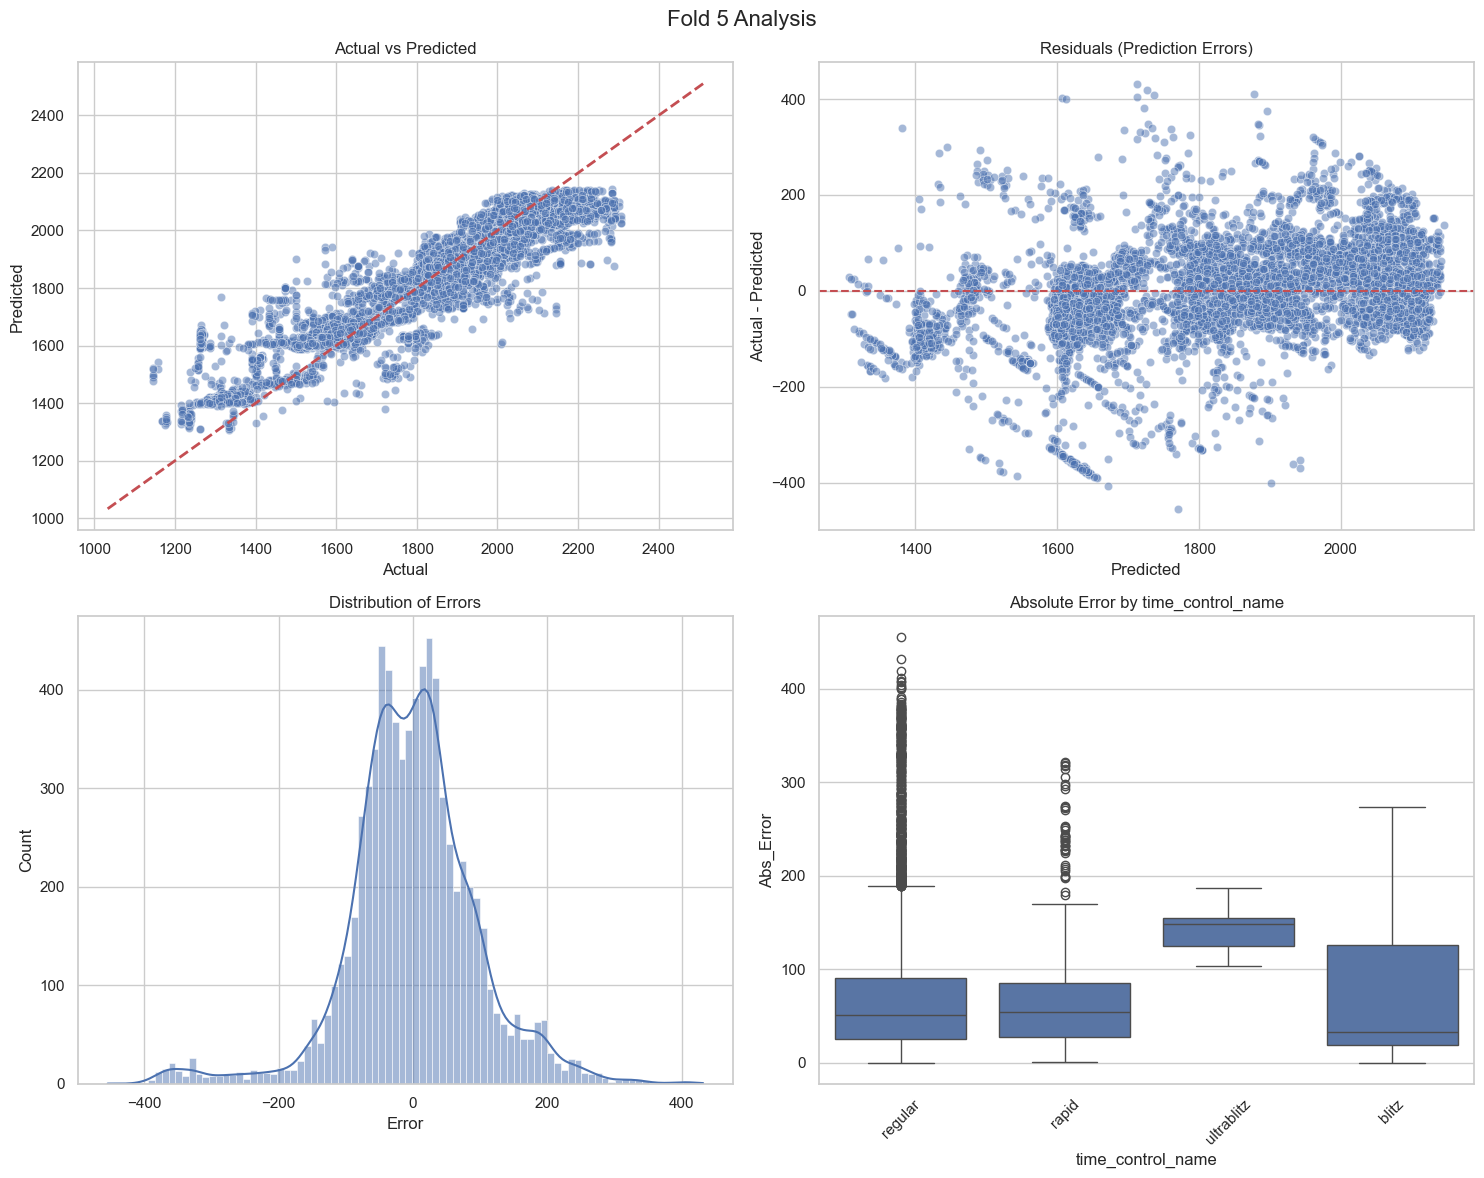

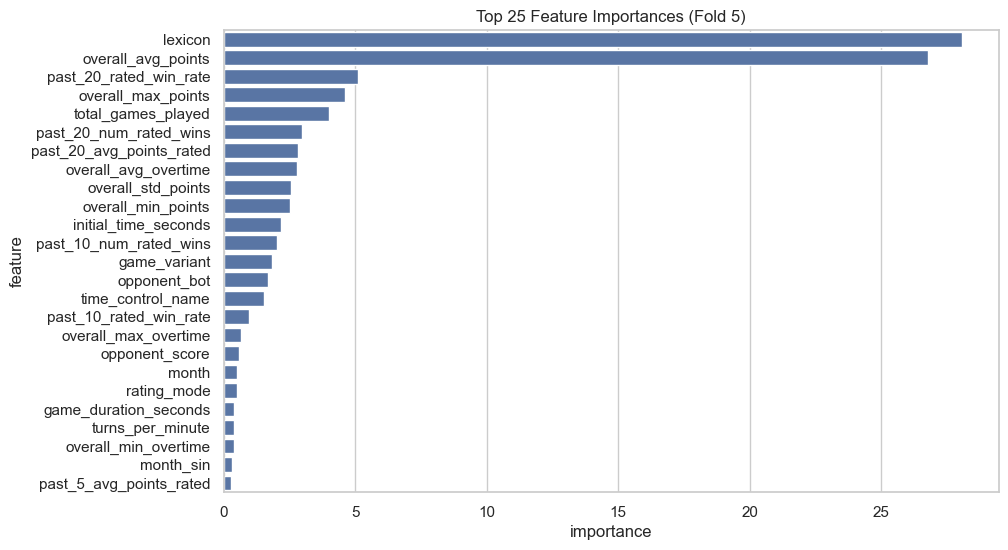


==================== SUMMARY ====================
Average Val RMSE over 5 folds: 103.4126
Std Dev Val RMSE: 9.4842


In [3]:


if not PKL_PATH.exists():
    raise FileNotFoundError(f"Could not find {PKL_PATH}")

with open(PKL_PATH, 'rb') as f:
    study = pickle.load(f)

print(f"Best params from study: {study.best_params}")

N_FOLDS = 5
gkf = GroupKFold(n_splits=N_FOLDS,)
fold_scores = []

for fold, (train_idx, val_idx) in enumerate(gkf.split(X, y, groups=groups)):
    print(f"\n{'='*20} FOLD {fold + 1}/{N_FOLDS} {'='*20}")
    
    X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]
    
    val_metadata = train_df.iloc[val_idx].copy() 

    print(f"Training set: {X_train.shape}")
    print(f"Validation set: {X_val.shape}")
    print(f"Distinct players in Val: {groups.iloc[val_idx].nunique()}")

    # Train Model
    model = get_model_and_params(MODEL_NAME, study.best_trial)
    pipeline = create_pipeline(model, needs_scaling=False)
    
    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_val)
    y_train_pred = pipeline.predict(X_train)

    val_rmse = np.sqrt(mean_squared_error(y_val, y_pred))
    train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
    fold_scores.append(val_rmse)

    print(f"\n--- Metrics ---")
    print(f"Train RMSE: {train_rmse:.4f}")
    print(f"Val   RMSE: {val_rmse:.4f}")
    print(f"Gap: {val_rmse - train_rmse:.4f}")

    # Create Analysis DataFrame 
    analysis_df = X_val.copy()
    analysis_df['nickname'] = val_metadata['nickname']
    analysis_df['Actual'] = y_val
    analysis_df['Predicted'] = y_pred
    analysis_df['Error'] = analysis_df['Actual'] - analysis_df['Predicted']
    analysis_df['Abs_Error'] = analysis_df['Error'].abs()

    # Show Top n Errors
    worst_errors = analysis_df.sort_values('Abs_Error', ascending=False)
    n = 10
    print(f"\nTop {n} Worst Predictions (Fold {fold+1}):")
    display(worst_errors[['nickname', 'Actual', 'Predicted', 'Error']].head(n))

    # Visualizations
    fig, axes = plt.subplots(2, 2, figsize=(15, 12))
    fig.suptitle(f'Fold {fold+1} Analysis', fontsize=16)

    # Actual vs Predicted
    sns.scatterplot(data=analysis_df, x='Actual', y='Predicted', alpha=0.5, ax=axes[0,0])
    axes[0,0].plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2)
    axes[0,0].set_title("Actual vs Predicted")

    # Residuals
    sns.scatterplot(data=analysis_df, x='Predicted', y='Error', alpha=0.5, ax=axes[0,1])
    axes[0,1].axhline(0, color='r', linestyle='--')
    axes[0,1].set_title("Residuals (Prediction Errors)")
    axes[0,1].set_ylabel("Actual - Predicted")

    # Error Distribution
    sns.histplot(data=analysis_df, x='Error', kde=True, ax=axes[1,0])
    axes[1,0].set_title("Distribution of Errors")

    # Error vs Feature
    categorial_feature = 'time_control_name'
    if categorial_feature in analysis_df.columns:
        sns.boxplot(data=analysis_df, x=categorial_feature, y='Abs_Error', ax=axes[1,1])
        axes[1,1].tick_params(axis='x', rotation=45)
        axes[1,1].set_title(f"Absolute Error by {categorial_feature}")

    plt.tight_layout()
    plt.show()

    # Feature Importance
    est = pipeline.steps[-1][1]
    n_feats = 25
    if hasattr(est, 'feature_importances_'):
        fi = pd.DataFrame({
            'feature': X_train.columns,
            'importance': est.feature_importances_
        }).sort_values('importance', ascending=False)
        
        plt.figure(figsize=(10, 6))
        sns.barplot(data=fi.head(n_feats), x='importance', y='feature')
        plt.title(f"Top {n_feats} Feature Importances (Fold {fold+1})")
        plt.show()


print(f"\n{'='*20} SUMMARY {'='*20}")
print(f"Average Val RMSE over {N_FOLDS} folds: {np.mean(fold_scores):.4f}")
print(f"Std Dev Val RMSE: {np.std(fold_scores):.4f}")

---

# Testing the model on a single fold

In [4]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, val_idx = next(splitter.split(X, y, groups=groups))

X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

val_metadata = train_df.iloc[val_idx].copy() 

print(f"Training set: {X_train.shape}")
print(f"Validation set: {X_val.shape}")
print(f"Distinct players in Train: {groups.iloc[train_idx].nunique()}")
print(f"Distinct players in Val: {groups.iloc[val_idx].nunique()}")

Training set: (30686, 111)
Validation set: (8266, 111)
Distinct players in Train: 661
Distinct players in Val: 166


In [5]:
if not PKL_PATH.exists():
    raise FileNotFoundError(f"Could not find {PKL_PATH}")

with open(PKL_PATH, 'rb') as f:
    study = pickle.load(f)

print(f"Best params from study: {study.best_params}")

model = get_model_and_params(MODEL_NAME, study.best_trial)
pipeline = create_pipeline(model, needs_scaling=False)

print("Training on local split...")
pipeline.fit(X_train, y_train)

y_pred = pipeline.predict(X_val)
y_train_pred = pipeline.predict(X_train)

val_rmse = np.sqrt(mean_squared_error(y_val, y_pred))
train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))

print(f"\n--- Results ---")
print(f"Train RMSE: {train_rmse:.4f}")
print(f"Val   RMSE: {val_rmse:.4f}")
print(f"Gap: {val_rmse - train_rmse:.4f}")


Best params from study: {'iterations': 388, 'depth': 7, 'learning_rate': 0.020042055065074078, 'l2_leaf_reg': 6.5325119246911125, 'border_count': 80}
Training on local split...

--- Results ---
Train RMSE: 60.1859
Val   RMSE: 99.0343
Gap: 38.8484


In [6]:
analysis_df = X_val.copy()
analysis_df['nickname'] = val_metadata['nickname']
analysis_df['Actual'] = y_val
analysis_df['Predicted'] = y_pred
analysis_df['Error'] = analysis_df['Actual'] - analysis_df['Predicted']
analysis_df['Abs_Error'] = analysis_df['Error'].abs()

worst_errors = analysis_df.sort_values('Abs_Error', ascending=False)

n = 10
print(f"Top {n} Worst Predictions:")
worst_errors[['nickname', 'Actual', 'Predicted', 'Error']].head(n)

Top 10 Worst Predictions:


,nickname,Actual,Predicted,Error
23643,Pasindu,2510,1589.473623,920.526377
12239,Pasindu,2510,1591.669437,918.330563
17135,Pasindu,2510,1592.488551,917.511449
8864,Pasindu,2510,1592.513496,917.486504
20161,Pasindu,2510,1594.317147,915.682853
36357,Pasindu,2510,1594.648326,915.351674
696,Pasindu,2510,1596.864112,913.135888
28114,Pasindu,2510,1596.894001,913.105999
8509,Pasindu,2289,1575.156344,713.843656
34191,Pasindu,2289,1588.381261,700.618739


## Visualization of Prediction Errors

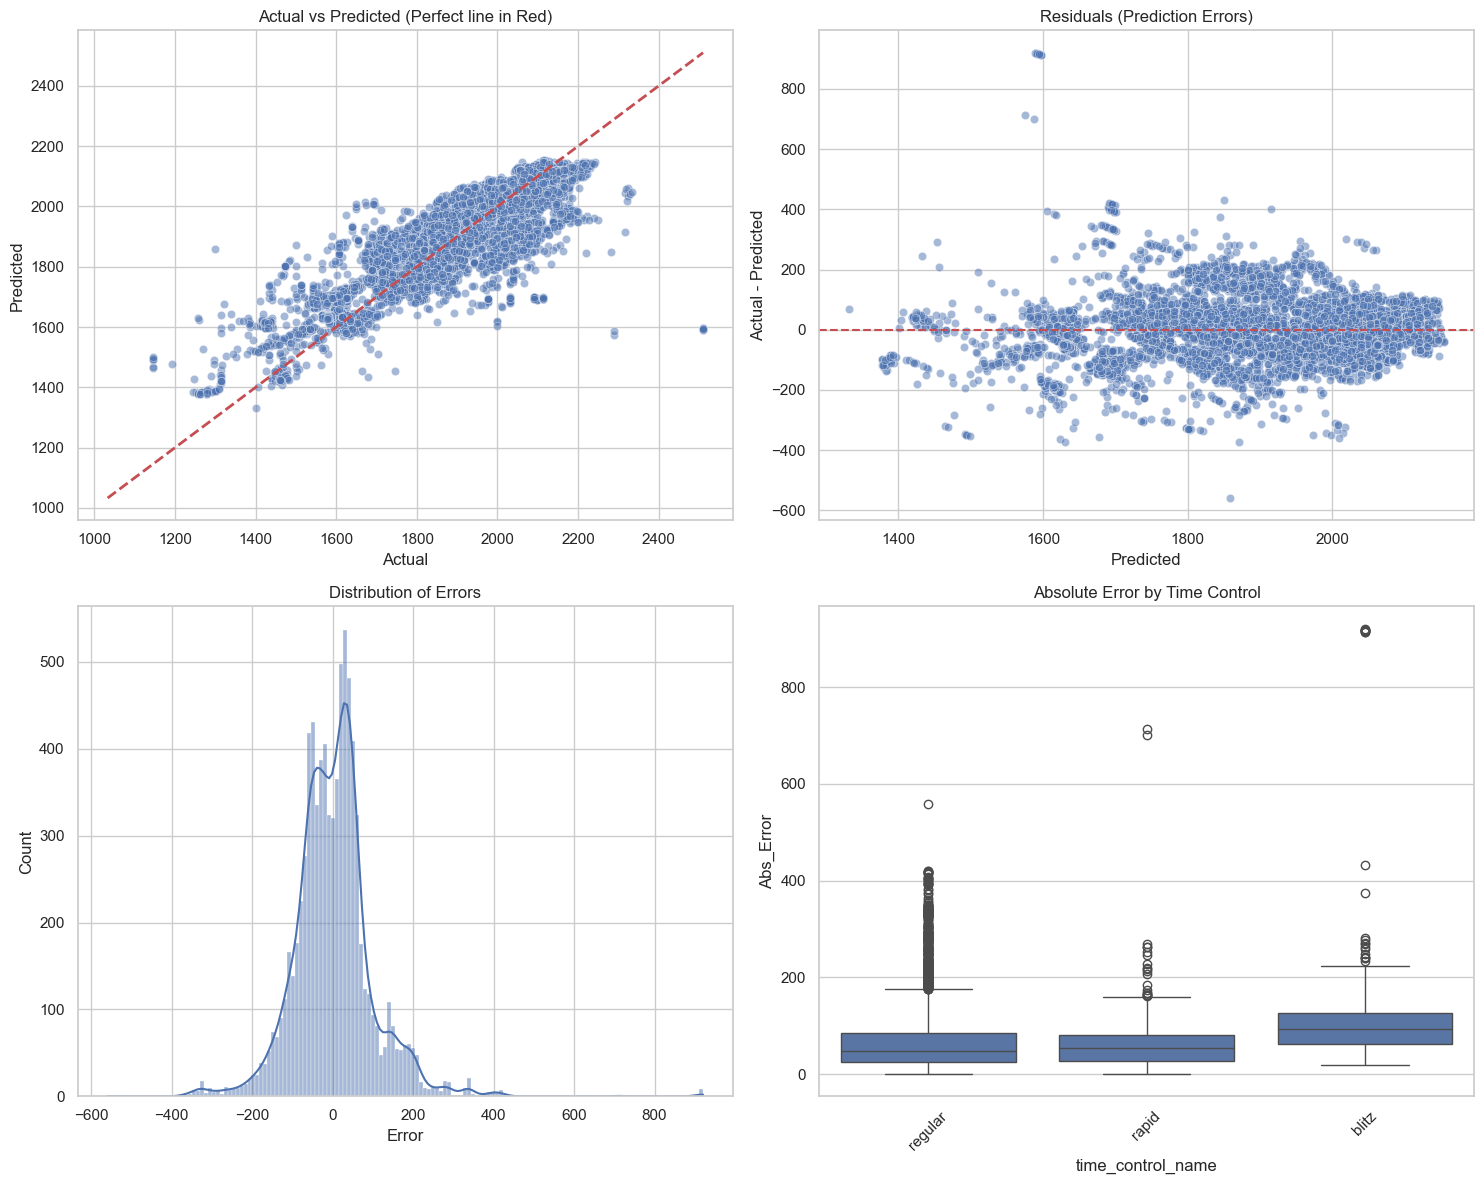

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

sns.scatterplot(data=analysis_df, x='Actual', y='Predicted', alpha=0.5, ax=axes[0,0])
axes[0,0].plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2)
axes[0,0].set_title("Actual vs Predicted (Perfect line in Red)")

sns.scatterplot(data=analysis_df, x='Predicted', y='Error', alpha=0.5, ax=axes[0,1])
axes[0,1].axhline(0, color='r', linestyle='--')
axes[0,1].set_title("Residuals (Prediction Errors)")
axes[0,1].set_ylabel("Actual - Predicted")

sns.histplot(data=analysis_df, x='Error', kde=True, ax=axes[1,0])
axes[1,0].set_title("Distribution of Errors")

# 4. Error vs a specific feature (Example: Time Control)
# Adjust 'time_control_name' to whatever categorical feature you suspect is tricky
categorial_feature = 'time_control_name'
# categorial_feature = 'rating_mode'
if categorial_feature in analysis_df.columns:
    sns.boxplot(data=analysis_df, x=categorial_feature, y='Abs_Error', ax=axes[1,1])
    axes[1,1].tick_params(axis='x', rotation=45)
    axes[1,1].set_title("Absolute Error by Time Control")

plt.tight_layout()
plt.show()

## Feature Importance

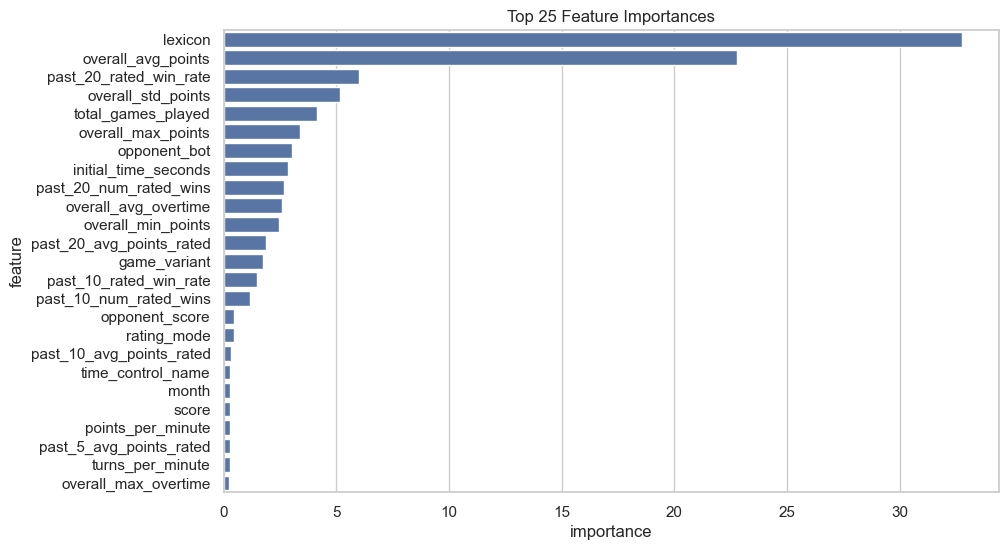

In [8]:
est = pipeline.steps[-1][1]
n = 25
if hasattr(est, 'feature_importances_'):
    fi = pd.DataFrame({
        'feature': X_train.columns,
        'importance': est.feature_importances_
    }).sort_values('importance', ascending=False)
    
    plt.figure(figsize=(10, 6))
    sns.barplot(data=fi.head(n), x='importance', y='feature')
    plt.title(f"Top {n} Feature Importances")
    plt.show()

# Testing on the entire dataset

In [9]:
# # %%
# # --- ANALYSIS ON FULL TRAINING SET ---

# print(f"\n{'='*20} FULL TRAINING SET ANALYSIS {'='*20}")

# # 1. Create and Fit Model on ALL Data
# # (We use the best params found in the study)
# model = get_model_and_params(MODEL_NAME, study.best_trial)
# pipeline = create_pipeline(model, needs_scaling=False)

# print(f"Fitting model on {X.shape[0]} samples...")
# pipeline.fit(X, y)

# # 2. Predict on ALL Data
# y_pred_full = pipeline.predict(X)

# # 3. Metrics
# train_rmse = np.sqrt(mean_squared_error(y, y_pred_full))
# print(f"\n--- Full Train Metrics ---")
# print(f"RMSE: {train_rmse:.4f}")
# print(f"MAE:  {mean_absolute_error(y, y_pred_full):.4f}")

# # 4. Create Analysis DataFrame
# # We use 'groups' (which contains nicknames) and 'X' (features)
# analysis_df = X.copy()
# analysis_df['nickname'] = groups # groups is the nickname series from clean_data
# analysis_df['Actual'] = y
# analysis_df['Predicted'] = y_pred_full
# analysis_df['Error'] = analysis_df['Actual'] - analysis_df['Predicted']
# analysis_df['Abs_Error'] = analysis_df['Error'].abs()

# # 5. Top Worst Predictions (Outlier/Glitch Hunting)
# worst_errors = analysis_df.sort_values('Abs_Error', ascending=False)
# n = 10
# print(f"\nTop {n} Worst Fits (Potential Data Errors?):")
# display(worst_errors[['nickname', 'Actual', 'Predicted', 'Error']].head(n))

# # 6. Visualizations
# fig, axes = plt.subplots(2, 2, figsize=(15, 12))
# fig.suptitle('Full Training Set Analysis', fontsize=16)

# # Actual vs Predicted
# sns.scatterplot(data=analysis_df, x='Actual', y='Predicted', alpha=0.3, ax=axes[0,0]) # Lower alpha for dense data
# axes[0,0].plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2)
# axes[0,0].set_title("Actual vs Predicted")

# # Residuals
# sns.scatterplot(data=analysis_df, x='Predicted', y='Error', alpha=0.3, ax=axes[0,1])
# axes[0,1].axhline(0, color='r', linestyle='--')
# axes[0,1].set_title("Residuals")
# axes[0,1].set_ylabel("Actual - Predicted")

# # Distribution
# sns.histplot(data=analysis_df, x='Error', kde=True, ax=axes[1,0])
# axes[1,0].set_title("Distribution of Errors")

# # Error by Category
# categorial_feature = 'time_control_name'
# if categorial_feature in analysis_df.columns:
#     sns.boxplot(data=analysis_df, x=categorial_feature, y='Abs_Error', ax=axes[1,1])
#     axes[1,1].tick_params(axis='x', rotation=45)
#     axes[1,1].set_title(f"Absolute Error by {categorial_feature}")

# plt.tight_layout()
# plt.show()

# # Feature Importance
# est = pipeline.steps[-1][1]
# n_feats = 25
# if hasattr(est, 'feature_importances_'):
#     fi = pd.DataFrame({
#         'feature': X.columns,
#         'importance': est.feature_importances_
#     }).sort_values('importance', ascending=False)
    
#     plt.figure(figsize=(10, 6))
#     sns.barplot(data=fi.head(n_feats), x='importance', y='feature')
#     plt.title(f"Top {n_feats} Feature Importances (Full Train)")
#     plt.show()

# Theory - Problematic players are players that play mostly Casual games.

In [ ]:
player_game_counts = train_df.groupby('nickname')['rating_mode'].value_counts().unstack(fill_value=0)
player_game_counts['total_games'] = player_game_counts.sum(axis=1)
player_game_counts['casual_percentage'] = player_game_counts['CASUAL'] / player_game_counts['total_games']

percentages = [0.99, 0.95, 0.9, 0.85, 0.8]
last_p = 1 
for p in percentages:
    problematic_players = player_game_counts[(player_game_counts['casual_percentage'] >= p) & (player_game_counts['casual_percentage'] < last_p)].index
    n_problematic = len(problematic_players)
    
    problematic_mask = val_metadata['nickname'].isin(problematic_players)
    n_problematic_in_val = problematic_mask.sum()
    
    if n_problematic_in_val == 0:
        print(f"\nNo problematic players found in validation set for threshold {p:.2f}.")
        continue
    
    problematic_errors = analysis_df[problematic_mask]
    non_problematic_errors = analysis_df[~problematic_mask]
    
    problematic_rmse = np.sqrt(mean_squared_error(problematic_errors['Actual'], problematic_errors['Predicted']))
    non_problematic_rmse = np.sqrt(mean_squared_error(non_problematic_errors['Actual'], non_problematic_errors['Predicted']))
    
    print(f"\n{'='*40}")
    print(f"Threshold for Problematic Players: Casual % >= {p:.2f} and < {last_p:.2f}")
    print(f"Number of Problematic Players: {n_problematic} (Games in Val: {n_problematic_in_val})")
    print(f"Problematic Players RMSE:     {problematic_rmse:.4f}")
    print(f"Non-Problematic Players RMSE: {non_problematic_rmse:.4f}")
    
    n = 10
    print(f"Top {n} Worst Predictions among Problematic Players (Showing worst game per player):")
    sorted_errors = problematic_errors.sort_values('Abs_Error', ascending=False)

    unique_worst_players = sorted_errors.drop_duplicates(subset=['nickname'], keep='first').copy()
    unique_worst_players['Casual %'] = unique_worst_players['nickname'].map(player_game_counts['casual_percentage'])
    unique_worst_players['Casual %'] = unique_worst_players['Casual %'].apply(lambda x: f"{x:.1%}")

    display(unique_worst_players[['nickname', 'Actual', 'Predicted', 'Error', 'Casual %']].head(n))
    last_p = p


No problematic players found in validation set for threshold 0.99.

Threshold for Problematic Players: Casual % >= 0.95 and < 1.00
Number of Problematic Players: 7 (Games in Val: 30)
Problematic Players RMSE:     193.6918
Non-Problematic Players RMSE: 99.6438

Threshold for Problematic Players: Casual % >= 0.90 and < 0.95
Number of Problematic Players: 9 (Games in Val: 610)
Problematic Players RMSE:     168.4428
Non-Problematic Players RMSE: 92.5605

Threshold for Problematic Players: Casual % >= 0.85 and < 0.90
Number of Problematic Players: 5 (Games in Val: 22)
Problematic Players RMSE:     58.3976
Non-Problematic Players RMSE: 100.2331

Threshold for Problematic Players: Casual % >= 0.80 and < 0.85
Number of Problematic Players: 8 (Games in Val: 70)
Problematic Players RMSE:     218.0650
Non-Problematic Players RMSE: 98.5319


## Statistical approach

In [11]:
import scipy.stats as stats
analysis_df['casual_pct'] = analysis_df['nickname'].map(player_game_counts['casual_percentage'])
analysis_df['casual_pct'] = analysis_df['casual_pct'].fillna(0)

corr, p_value = stats.spearmanr(analysis_df['casual_pct'], analysis_df['Abs_Error'])

print(f"\n--- Correlation Analysis ---")
print(f"Spearman Correlation (Casual % vs Abs Error): {corr:.4f}")
print(f"P-value: {p_value:.4e}")

if p_value < 0.05:
    print("Result: There is a Statistically Significant relationship.")
    if corr > 0:
        print("Direction: Positive (Higher Casual % -> Higher Error)")
    else:
        print("Direction: Negative (Higher Casual % -> Lower Error)")
else:
    print("Result: No statistically significant relationship found.")


--- Correlation Analysis ---
Spearman Correlation (Casual % vs Abs Error): 0.0985
P-value: 2.8026e-19
Result: There is a Statistically Significant relationship.
Direction: Positive (Higher Casual % -> Higher Error)


C:\Users\selad\AppData\Local\Temp\ipykernel_12936\611603215.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


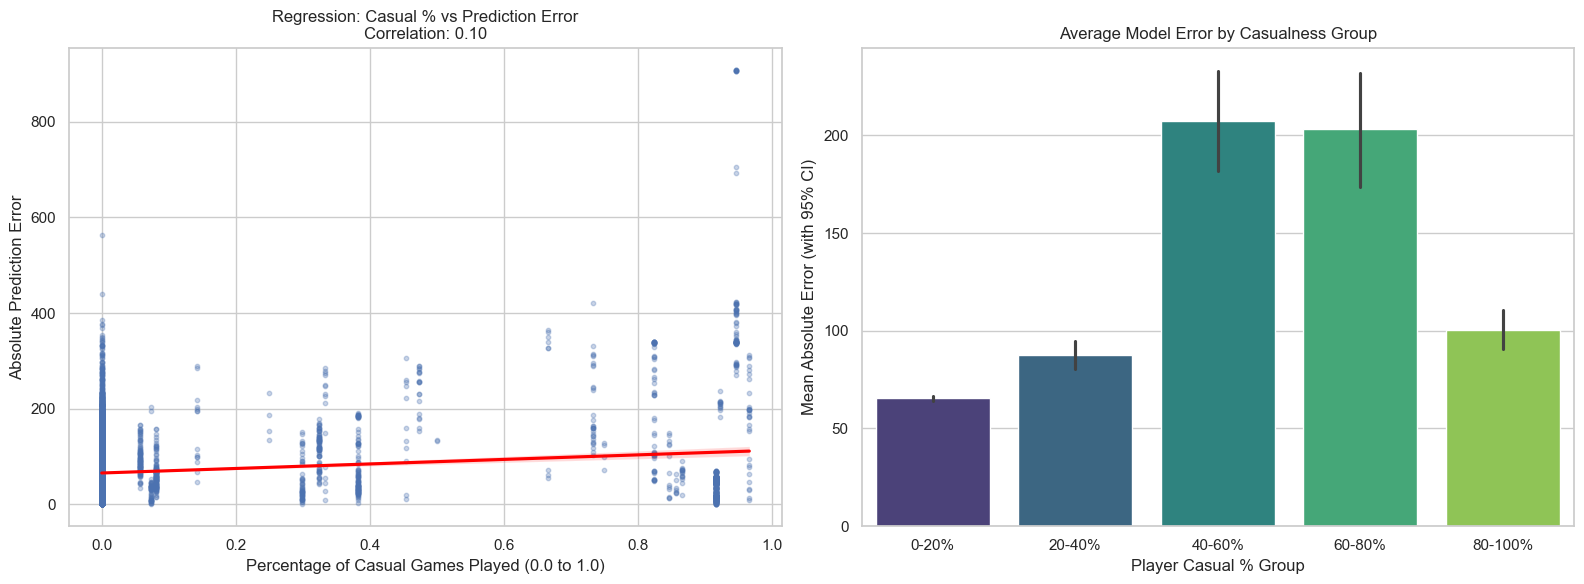

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Scatter with Regression Line
# This answers: "Does error go up as casualness goes up?"
sns.regplot(
    data=analysis_df, 
    x='casual_pct', 
    y='Abs_Error', 
    scatter_kws={'alpha': 0.3, 's': 10}, 
    line_kws={'color': 'red'},
    ax=axes[0]
)
axes[0].set_title(f"Regression: Casual % vs Prediction Error\nCorrelation: {corr:.2f}")
axes[0].set_xlabel("Percentage of Casual Games Played (0.0 to 1.0)")
axes[0].set_ylabel("Absolute Prediction Error")

# Plot 2: Binned Error Analysis (The "Bucket" view)
# We group players into bins (0-20%, 20-40%, etc.) to see the average error per group
analysis_df['casual_bin'] = pd.cut(analysis_df['casual_pct'], bins=5, labels=["0-20%", "20-40%", "40-60%", "60-80%", "80-100%"])

sns.barplot(
    data=analysis_df, 
    x='casual_bin', 
    y='Abs_Error', 
    palette="viridis",
    ax=axes[1]
)
axes[1].set_title("Average Model Error by Casualness Group")
axes[1].set_xlabel("Player Casual % Group")
axes[1].set_ylabel("Mean Absolute Error (with 95% CI)")

plt.tight_layout()
plt.show()

In [13]:

THRESHOLD = 0.95

group_casual = analysis_df[analysis_df['casual_pct'] >= THRESHOLD]['Abs_Error']
group_serious = analysis_df[analysis_df['casual_pct'] < THRESHOLD]['Abs_Error']

# Perform Mann-Whitney U Test
stat, p_val = stats.mannwhitneyu(group_casual, group_serious, alternative='greater')

print(f"\n--- Hypothesis Test (Threshold > {THRESHOLD*100}%) ---")
print(f"Avg Error for Mostly Casual Players:  {group_casual.mean():.2f}")
print(f"Avg Error for Serious/Mixed Players:  {group_serious.mean():.2f}")
print(f"Mann-Whitney U Statistic: {stat}")
print(f"P-Value: {p_val:.4e}")

if p_val < 0.05:
    print(f"CONCLUSION: We reject the null hypothesis.\nThe model makes SIGNIFICANTLY larger errors on players with >={THRESHOLD*100}% casual games.")
else:
    print(f"CONCLUSION: We cannot reject the null hypothesis.\nThe difference in errors is likely due to chance.")


--- Hypothesis Test (Threshold > 95.0%) ---
Avg Error for Mostly Casual Players:  170.74
Avg Error for Serious/Mixed Players:  70.07
Mann-Whitney U Statistic: 198140.0
P-Value: 5.3936e-09
CONCLUSION: We reject the null hypothesis.
The model makes SIGNIFICANTLY larger errors on players with >=95.0% casual games.


# Theory - Problematic players have shorter games

## shap

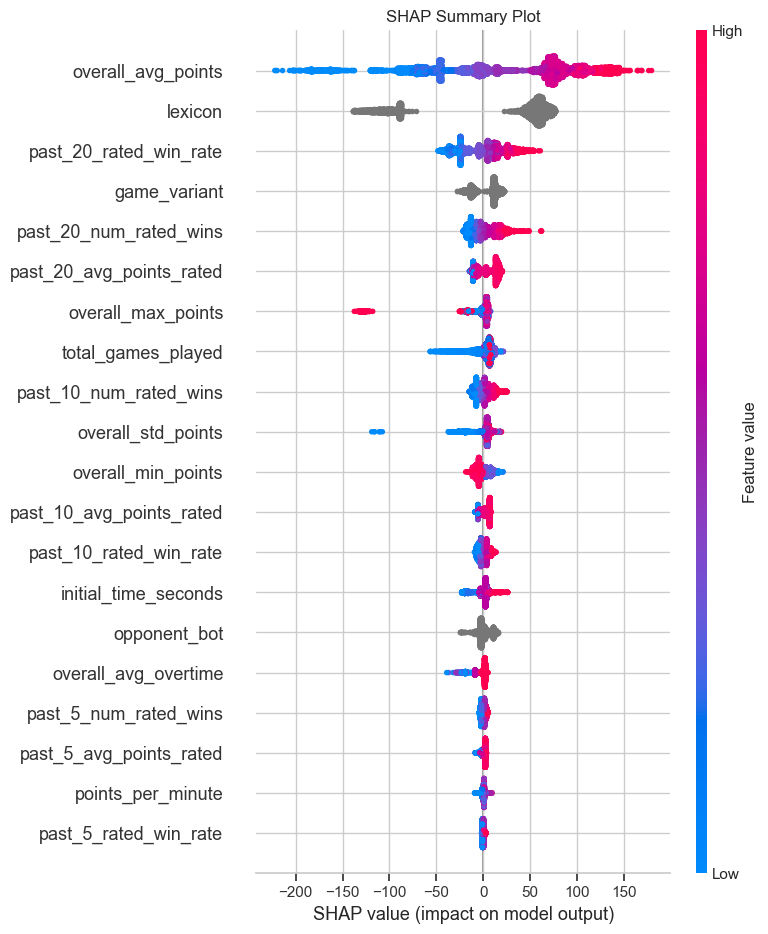

Explaining Worst Prediction: Player Pasindu
Actual: 2510, Predicted: 1601.2136465714925


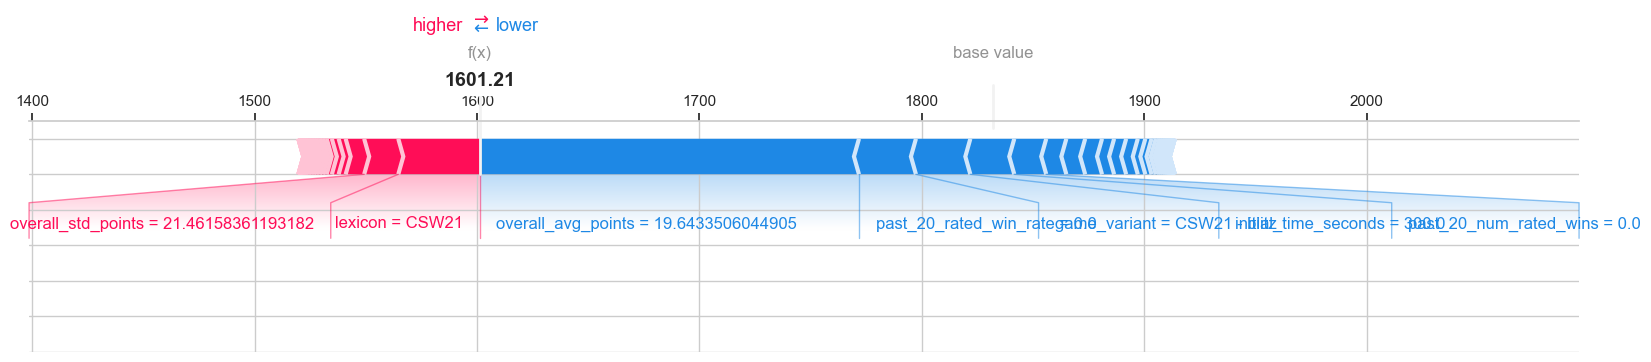

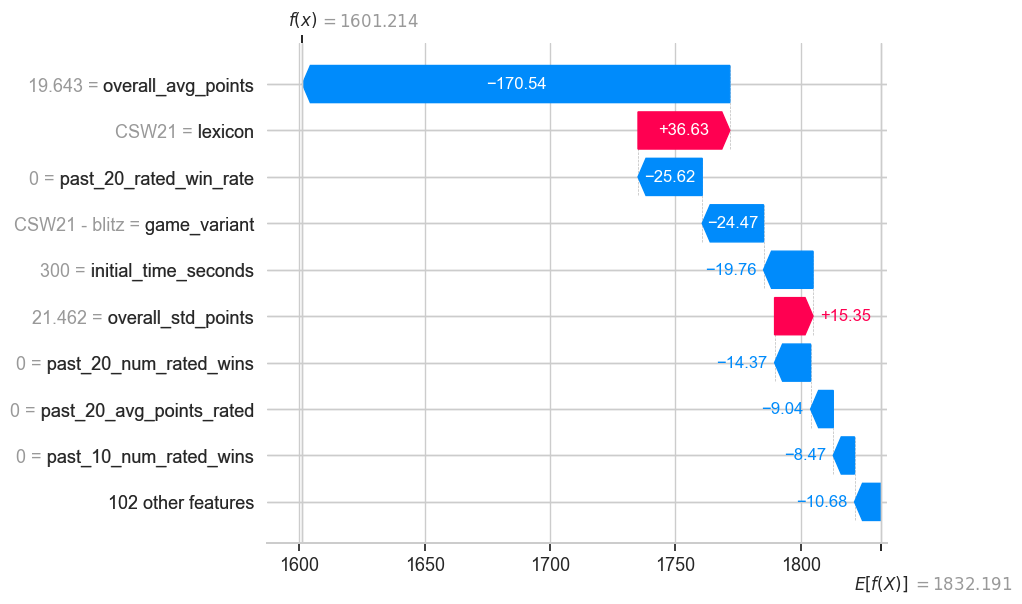

In [15]:
# generated using gemini-2.5 pro
import shap

explainer = shap.TreeExplainer(pipeline.steps[-1][1])

# 2. Calculate SHAP values for the Validation Set
# (We need to transform X_val using the pipeline's preprocessor first if you have one)
# If no preprocessor, use X_val directly.
# Assuming 'pipeline.steps[0]' is just the model if you have no scaling:
X_val_processed = X_val # Or pipeline[:-1].transform(X_val) if you have scalers

shap_values = explainer.shap_values(X_val_processed)

# 3. VISUALIZATION 1: Summary Plot (Global View)
# Shows not just *what* is important, but *how* (e.g., Does High Time Control = High Rating?)
plt.title("SHAP Summary Plot")
shap.summary_plot(shap_values, X_val_processed)

# 4. VISUALIZATION 2: The "Why did it fail?" Plot
# Let's look at the SHAP force plot for your WORST prediction
worst_idx = analysis_df['Abs_Error'].idxmax()
# We need the integer location (iloc) of this index in X_val
loc_idx = X_val.index.get_loc(worst_idx)

print(f"Explaining Worst Prediction: Player {analysis_df.loc[worst_idx, 'nickname']}")
print(f"Actual: {analysis_df.loc[worst_idx, 'Actual']}, Predicted: {analysis_df.loc[worst_idx, 'Predicted']}")

shap.plots.force(
    explainer.expected_value, 
    shap_values[loc_idx], 
    X_val_processed.iloc[loc_idx],
    matplotlib=True
)
# waterfall plot 
shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[loc_idx],
        base_values=explainer.expected_value,
        data=X_val_processed.iloc[loc_idx],
        feature_names=X_val_processed.columns.tolist()
    )
)

# error by slicing 

C:\Users\selad\AppData\Local\Temp\ipykernel_12936\2860336088.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  bin_performance = analysis_df.groupby('rating_bin')[['Error', 'Abs_Error']].agg(['mean', 'count'])


Error         Abs_Error      
                  mean count        mean count
rating_bin                                    
1000-1300  -178.793204    44  178.793204    44
1300-1600   -90.579224   884   94.666021   884
1600-1900   -29.031756  2562   63.215334  2562
1900-2200    35.056939  4701   66.195647  4701
2200-2500   153.516106    67  153.516106    67
2500+       906.965738     8  906.965738     8

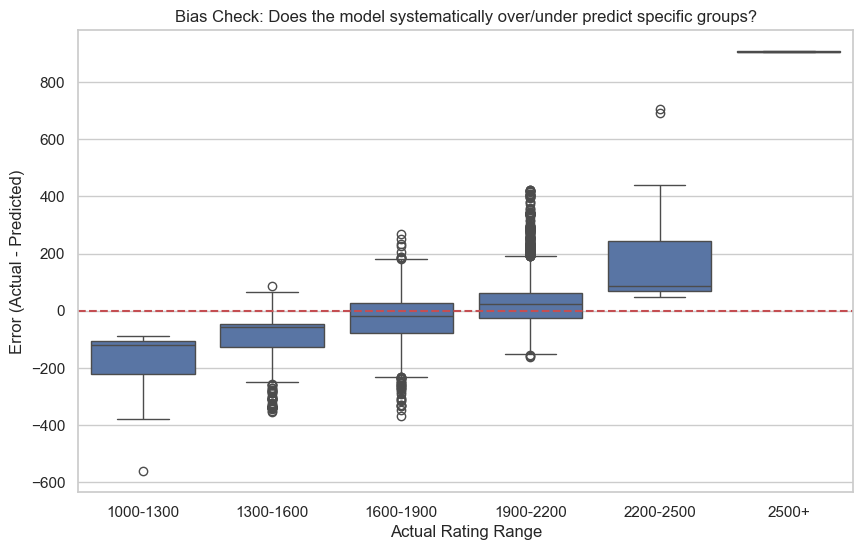

In [16]:
analysis_df['rating_bin'] = pd.cut(
    analysis_df['Actual'], 
    bins=[1000, 1300, 1600, 1900, 2200, 2500, np.inf],
    labels=['1000-1300', '1300-1600', '1600-1900', '1900-2200', '2200-2500', '2500+']
)

bin_performance = analysis_df.groupby('rating_bin')[['Error', 'Abs_Error']].agg(['mean', 'count'])
display(bin_performance)

plt.figure(figsize=(10, 6))
sns.boxplot(data=analysis_df, x='rating_bin', y='Error')
plt.axhline(0, color='r', linestyle='--')
plt.title("Bias Check: Does the model systematically over/under predict specific groups?")
plt.xlabel("Actual Rating Range")
plt.ylabel("Error (Actual - Predicted)")
plt.show()

# Analysis: The "Cold Start" Problem


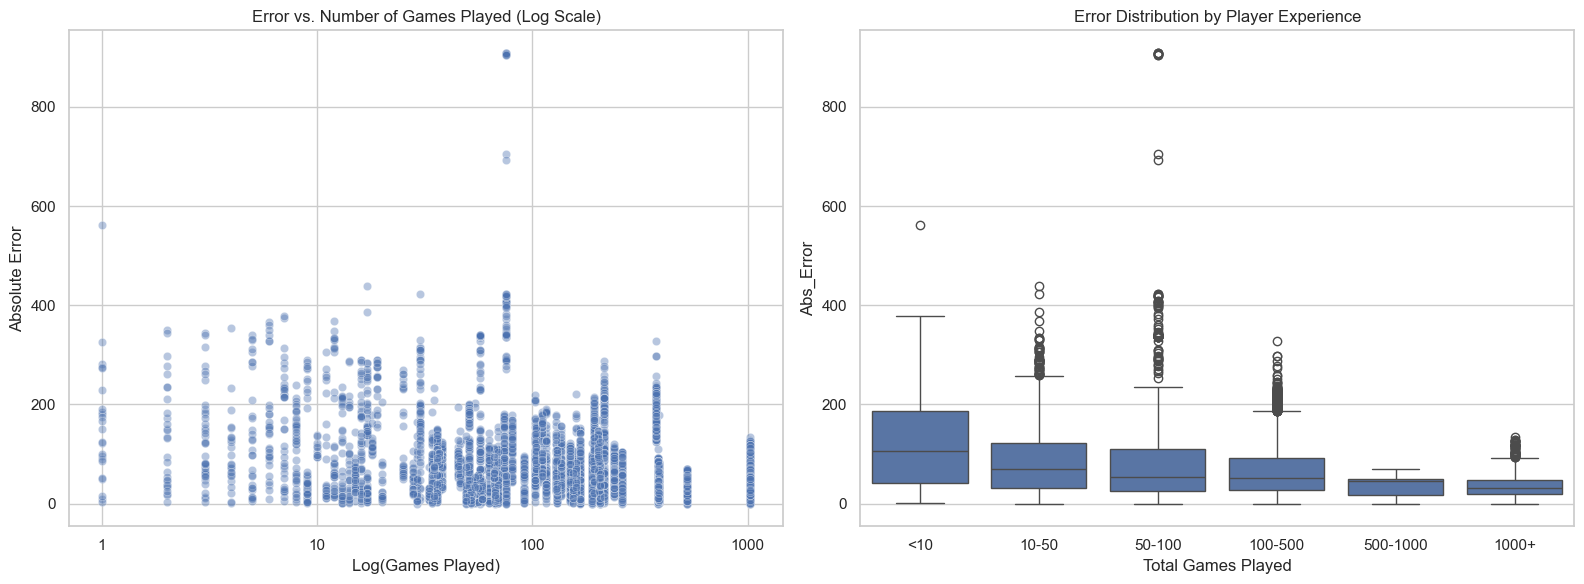

RMSE for New Players (<100 games): 139.8700
RMSE for Veterans (>500 games):   43.9728


In [62]:
# 1. Calculate game count per player in the FULL dataset (or train set)
player_game_counts_total = train_df['nickname'].value_counts()

# 2. Map this to your validation analysis dataframe
analysis_df['games_played'] = analysis_df['nickname'].map(player_game_counts_total)

# 3. Visualize
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Log scale often makes this clearer as game counts follow a power law
sns.scatterplot(data=analysis_df, x='games_played', y='Abs_Error', alpha=0.4, ax=axes[0])
axes[0].set_xscale('log')
axes[0].set_title("Error vs. Number of Games Played (Log Scale)")
axes[0].set_xlabel("Log(Games Played)")
axes[0].set_ylabel("Absolute Error")
axes[0].get_xaxis().set_major_formatter(plt.ScalarFormatter())

# Binning for clarity
analysis_df['experience_bin'] = pd.cut(
    analysis_df['games_played'], 
    bins=[0, 10, 50, 100, 500, 1000, np.inf],
    labels=['<10', '10-50', '50-100', '100-500', '500-1000', '1000+']
)

sns.boxplot(data=analysis_df, x='experience_bin', y='Abs_Error', ax=axes[1])
axes[1].set_title("Error Distribution by Player Experience")
axes[1].set_xlabel("Total Games Played")

plt.tight_layout()
plt.show()

low_bound = 100
high_bound = 500
low_exp_rmse = np.sqrt(mean_squared_error(
    analysis_df[analysis_df['games_played'] < low_bound]['Actual'], 
    analysis_df[analysis_df['games_played'] < low_bound]['Predicted']
))
high_exp_rmse = np.sqrt(mean_squared_error(
    analysis_df[analysis_df['games_played'] > high_bound]['Actual'], 
    analysis_df[analysis_df['games_played'] > high_bound]['Predicted']
))

print(f"RMSE for New Players (<{low_bound} games): {low_exp_rmse:.4f}")
print(f"RMSE for Veterans (>{high_bound} games):   {high_exp_rmse:.4f}")

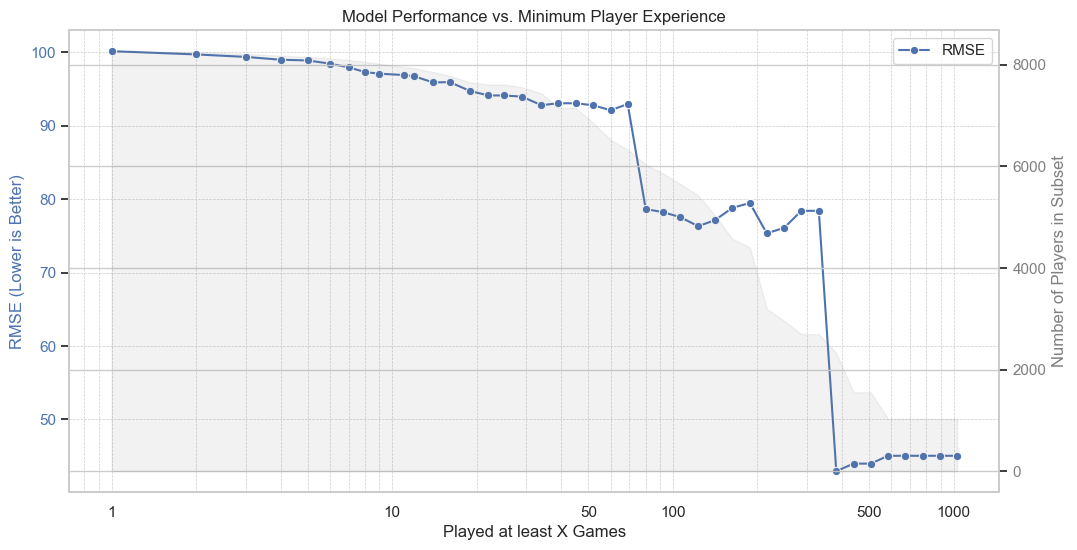

In [57]:

max_games = analysis_df['games_played'].max()
thresholds = np.unique(np.geomspace(1, max_games, num=50).astype(int))

results_rmse = []
results_count = []
valid_thresholds = []

for t in thresholds:
    subset = analysis_df[analysis_df['games_played'] >= t]
    
    if len(subset) > 5:
        rmse = np.sqrt(mean_squared_error(subset['Actual'], subset['Predicted']))
        results_rmse.append(rmse)
        results_count.append(len(subset))
        valid_thresholds.append(t)

fig, ax1 = plt.subplots(figsize=(12, 6))

sns.lineplot(x=valid_thresholds, y=results_rmse, marker='o', ax=ax1, color='b', label='RMSE')
ax1.set_xlabel('Played at least X Games')
ax1.set_ylabel('RMSE (Lower is Better)', color='b')
ax1.tick_params(axis='y', labelcolor='b')
ax1.set_title('Model Performance vs. Minimum Player Experience')

ax2 = ax1.twinx()
ax2.fill_between(valid_thresholds, results_count, color='gray', alpha=0.1, label='Sample Size')
ax2.set_ylabel('Number of Players in Subset', color='gray')
ax2.tick_params(axis='y', labelcolor='gray')

ax1.grid(True, which='both', linestyle='--', linewidth=0.5)
ax1.set_xscale('log')
ax1.set_xticks([1, 10, 50, 100, 500, 1000])
ax1.get_xaxis().set_major_formatter(plt.ScalarFormatter())

plt.show()

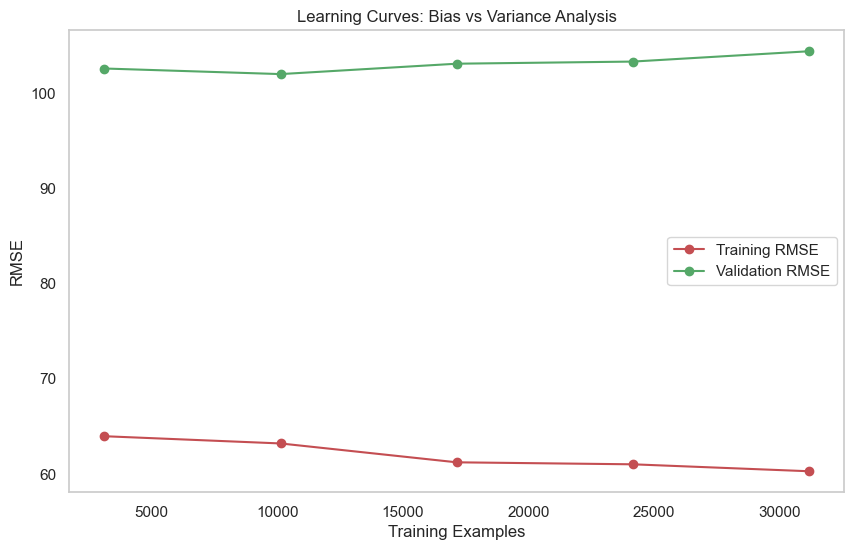

Interpretation:
- High Gap between lines = Overfitting (Need more data or regularization)
- Low Gap but high error = Underfitting (Need more complex model/features)


In [ ]:
from sklearn.model_selection import learning_curve

train_sizes, train_scores, val_scores = learning_curve(
    estimator=pipeline,
    X=X,
    y=y,
    groups=groups,
    train_sizes=np.linspace(0.1, 1.0, 5),
    cv=gkf, 
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

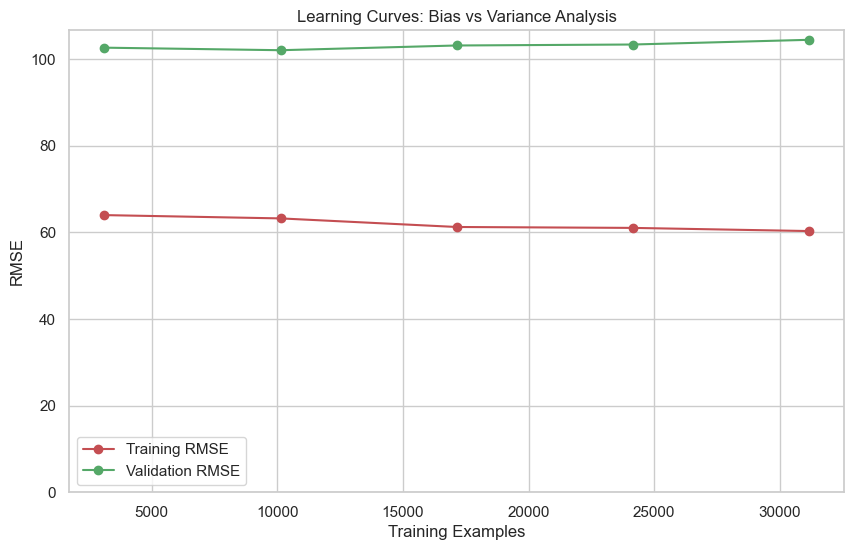

Interpretation:
- High Gap between lines = Overfitting (Need more data or regularization)
- Low Gap but high error = Underfitting (Need more complex model/features)


In [ ]:
train_scores_mean = -np.mean(train_scores, axis=1)
val_scores_mean = -np.mean(val_scores, axis=1)

plt.figure(figsize=(10, 6))
plt.plot(train_sizes, train_scores_mean, 'o-', color="r", label="Training RMSE")
plt.plot(train_sizes, val_scores_mean, 'o-', color="g", label="Validation RMSE")
plt.title("Learning Curves: Bias vs Variance Analysis")
plt.xlabel("Training Examples")
plt.ylabel("RMSE")
plt.legend(loc="best")
plt.grid(True)
plt.ylim(bottom=0)

plt.show()

print("Interpretation:")
print("- High Gap between lines = Overfitting (Need more data or regularization)")
print("- Low Gap but high error = Underfitting (Need more complex model/features)")